# 01 — Data Prep

Turns the raw NESO half-hourly demand data (2021–2025) into a clean **daily** series with calendar features, saved to `data/processed/daily_demand.csv`.

Steps:
1. Load all yearly files and parse dates (formats differ between years).
2. Build **correct timestamps**, including the clock-change days that have 46 or 50 settlement periods.
3. Detect and clean isolated **spikes** (e.g. the suspicious summer-2025 values).
4. Aggregate to **daily** values by grouping on the settlement date.
5. Add **calendar features** (day of week, month, weekend, England & Wales bank holidays, Christmas period).
6. Save the processed dataset.

In [1]:
import glob
import os

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)

## 1. Load the raw files

In [2]:
# Works whether the notebook runs from notebooks/ or the project root
raw_path = "data/raw" if os.path.exists("data/raw") else "../data/raw"
processed_path = raw_path.replace("raw", "processed")

files = sorted(glob.glob(f"{raw_path}/*.csv"))
print(f"Found {len(files)} files:")
for f in files:
    print(" ", f)

# Only the columns we need. Solar columns are kept for EDA only (not model inputs).
KEEP = ["SETTLEMENT_DATE", "SETTLEMENT_PERIOD", "ND", "TSD",
        "EMBEDDED_SOLAR_GENERATION", "EMBEDDED_SOLAR_CAPACITY"]

# source_file records which yearly file each row came from (used in the date-order check)
df = pd.concat(
    [pd.read_csv(f, usecols=KEEP).assign(source_file=os.path.basename(f)) for f in files],
    ignore_index=True,
)
print("\nCombined shape:", df.shape)

Found 5 files:
  ../data/raw/demanddata_2021.csv
  ../data/raw/demanddata_2022.csv
  ../data/raw/demanddata_2023.csv
  ../data/raw/demanddata_2024.csv
  ../data/raw/demanddata_2025.csv

Combined shape: (87648, 7)


## 2. Parse dates and build correct timestamps

Two problems to handle:

- **Date formats differ between files** (`01-JAN-2022` vs `01-Jan-23`), so we parse with `format="mixed", dayfirst=True`.
- **Clock-change days.** Settlement periods are in UK local time. The spring change day has **46** periods and the autumn one has **50**. The naive formula `date + (period - 1) * 30 min` turns periods 49–50 into 24:00 and 24:30, which collide with the next day's 00:00 and 00:30.

Fix: start from local midnight (which always exists in UK time), convert it to UTC, then add the period offset. UTC has no clock changes, so every half-hour gets a unique timestamp.

In [3]:
# --- Parse dates with explicit formats (no guessing, so day and month can't be swapped) ---
s = df["SETTLEMENT_DATE"].astype(str).str.strip()

fmt_long  = s.str.fullmatch(r"\d{2}-[A-Za-z]{3}-\d{4}")   # 01-JAN-2022
fmt_short = s.str.fullmatch(r"\d{2}-[A-Za-z]{3}-\d{2}")   # 01-Jan-23
fmt_iso   = s.str.match(r"\d{4}-\d{2}-\d{2}")             # 2025-01-08 (any time part ignored)

df["date"] = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
df.loc[fmt_long,  "date"] = pd.to_datetime(s[fmt_long],  format="%d-%b-%Y")
df.loc[fmt_short, "date"] = pd.to_datetime(s[fmt_short], format="%d-%b-%y")
df.loc[fmt_iso,   "date"] = pd.to_datetime(s[fmt_iso].str[:10], format="%Y-%m-%d")

print("Rows per date format:  long:", fmt_long.sum(), " short:", fmt_short.sum(), " ISO:", fmt_iso.sum())
unparsed = df["date"].isna().sum()
print("Unparsed dates:", unparsed)
assert unparsed == 0, "Some SETTLEMENT_DATE values match none of the known formats"

# --- Order check: within each file, parsed dates must never go backwards ---
# Must run BEFORE sorting, while rows are still in the file's original order.
in_order = df.groupby("source_file", sort=False)["date"].apply(lambda d: d.is_monotonic_increasing)
print("\nDates in order within each file:")
print(in_order)
assert in_order.all(), "A file's dates go backwards after parsing, so the parse is wrong"

# --- Build timestamps (unchanged from before) ---
# Naive version, kept only to show the clock-change problem
naive_ts = df["date"] + pd.to_timedelta((df["SETTLEMENT_PERIOD"] - 1) * 30, unit="m")

# Correct version: local midnight -> UTC -> add period offset
offset = pd.to_timedelta((df["SETTLEMENT_PERIOD"] - 1) * 30, unit="m")
df["datetime_utc"] = df["date"].dt.tz_localize("Europe/London").dt.tz_convert("UTC") + offset
df["datetime_local"] = df["datetime_utc"].dt.tz_convert("Europe/London")

df = df.sort_values("datetime_utc").reset_index(drop=True)

print("\nDate range:", df["date"].min().date(), "->", df["date"].max().date())
print("Duplicate timestamps (naive formula):  ", naive_ts.duplicated().sum())
print("Duplicate timestamps (UTC-based fix):  ", df["datetime_utc"].duplicated().sum())

Rows per date format:  long: 52608  short: 17520  ISO: 17520
Unparsed dates: 0

Dates in order within each file:
source_file
demanddata_2021.csv    True
demanddata_2022.csv    True
demanddata_2023.csv    True
demanddata_2024.csv    True
demanddata_2025.csv    True
Name: date, dtype: bool

Date range: 2021-01-01 -> 2025-12-31
Duplicate timestamps (naive formula):   10
Duplicate timestamps (UTC-based fix):   0


### Check: periods per day

In [4]:
periods_per_day = df.groupby("date").size()
print("Days by number of periods:")
print(periods_per_day.value_counts().sort_index())

print("\nDays that are not 48 periods (expected: clock-change days only):")
print(periods_per_day[periods_per_day != 48])

Days by number of periods:
46       5
48    1816
50       5
Name: count, dtype: int64

Days that are not 48 periods (expected: clock-change days only):
date
2021-03-28    46
2021-10-31    50
2022-03-27    46
2022-10-30    50
2023-03-26    46
2023-10-29    50
2024-03-31    46
2024-10-27    50
2025-03-30    46
2025-10-26    50
dtype: int64


## 3. Spike detection

A spike is an isolated half-hour far away from its neighbours. Each value is compared with the **rolling median of the 7 surrounding half-hours** (±1.5 hours). The median ignores a single extreme value, so a spike stands out clearly against it.

`SPIKE_THRESHOLD_MW` is deliberately large: normal morning ramps move by roughly 2,000 MW per half-hour, so a deviation of 8,000 MW is not normal behaviour.

In [5]:
SPIKE_THRESHOLD_MW = 8000

rolling_median = df["ND"].rolling(window=7, center=True, min_periods=1).median()
df["nd_deviation"] = df["ND"] - rolling_median
df["is_spike"] = df["nd_deviation"].abs() > SPIKE_THRESHOLD_MW

print(f"Spikes flagged: {df['is_spike'].sum()}")
print("\nSpikes per year:")
print(df.loc[df["is_spike"], "date"].dt.year.value_counts().sort_index())

print("\nFlagged rows (TSD shown for comparison: if TSD jumps too, the event may be real):")
df.loc[df["is_spike"], ["datetime_local", "SETTLEMENT_PERIOD", "ND", "TSD", "nd_deviation"]] \
  .sort_values("nd_deviation", ascending=False).head(20)

Spikes flagged: 0

Spikes per year:
Series([], Name: count, dtype: int64)

Flagged rows (TSD shown for comparison: if TSD jumps too, the event may be real):


,datetime_local,SETTLEMENT_PERIOD,ND,TSD,nd_deviation


In [6]:
# Summer-2025 check: the largest May–September 2025 values
summer_2025 = df[(df["date"].dt.year == 2025) & (df["date"].dt.month.between(5, 9))]
summer_2025.nlargest(10, "ND")[["datetime_local", "SETTLEMENT_PERIOD", "ND", "TSD", "is_spike"]]

,datetime_local,SETTLEMENT_PERIOD,ND,TSD,is_spike
83172,2025-09-29 19:00:00+01:00,39,33391,35153,False
83220,2025-09-30 19:00:00+01:00,39,33179,35510,False
83173,2025-09-29 19:30:00+01:00,40,32992,34635,False
83171,2025-09-29 18:30:00+01:00,38,32888,35305,False
82836,2025-09-22 19:00:00+01:00,39,32835,34846,False
82932,2025-09-24 19:00:00+01:00,39,32709,34705,False
83170,2025-09-29 18:00:00+01:00,37,32699,35141,False
82933,2025-09-24 19:30:00+01:00,40,32671,34670,False
82885,2025-09-23 19:30:00+01:00,40,32661,34656,False
83219,2025-09-30 18:30:00+01:00,38,32641,35489,False


In [7]:
# Zoom in on the biggest spike (±2 days) to see it in context
if df["is_spike"].any():
    centre = df.loc[df["nd_deviation"].abs().idxmax(), "datetime_utc"]
    window = df[(df["datetime_utc"] >= centre - pd.Timedelta(days=2)) &
                (df["datetime_utc"] <= centre + pd.Timedelta(days=2))]

    plt.figure(figsize=(14, 4))
    plt.plot(window["datetime_local"], window["ND"], linewidth=0.8, label="ND")
    spikes = window[window["is_spike"]]
    plt.scatter(spikes["datetime_local"], spikes["ND"], color="red", zorder=3, label="flagged spike")
    plt.title("Largest flagged spike in context (±2 days)")
    plt.ylabel("Demand (MW)")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No spikes flagged at this threshold.")

No spikes flagged at this threshold.


### Decision: clean the spikes

If the flagged values are isolated single half-hours that jump far above their neighbours (and TSD doesn't move with them), treat them as data errors: set them to missing and interpolate from the surrounding half-hours. Set `CLEAN_SPIKES = False` if you decide they are real.

In [8]:
CLEAN_SPIKES = True

if CLEAN_SPIKES:
    df["ND_clean"] = df["ND"].mask(df["is_spike"]).interpolate(limit_direction="both")
else:
    df["ND_clean"] = df["ND"]

print("Values changed:", (df["ND_clean"] != df["ND"]).sum())
print("Max ND before:", df["ND"].max(), " after:", round(df["ND_clean"].max()))

Values changed: 0
Max ND before: 46433  after: 46433


## 4. Aggregate to daily values

We **group by the settlement date**, not by timestamp, because NESO already assigns every period (including periods 47–50 on the autumn clock-change day) to the correct day.

**Target choice: daily *mean* demand (MW), not the daily *sum*.** A sum is distorted on clock-change days: the 23-hour day looks about 4% low and the 25-hour day about 4% high. Those are artificial dips and spikes a model would try to learn. The mean is unaffected by the number of periods. Energy (MWh) and peak demand are kept as extra columns.

In [9]:
daily = (
    df.groupby("date")
      .agg(demand_mw=("ND_clean", "mean"),
           peak_mw=("ND_clean", "max"),
           energy_mwh=("ND_clean", lambda s: s.sum() * 0.5),   # MW x 0.5 h = MWh
           n_periods=("ND_clean", "size"),
           solar_capacity_mw=("EMBEDDED_SOLAR_CAPACITY", "mean"),
           solar_generation_mw=("EMBEDDED_SOLAR_GENERATION", "mean"))
)

# Make sure every calendar day exists (missing days would appear as NaN)
daily = daily.asfreq("D")
daily.index.name = "date"

missing_days = daily["demand_mw"].isna().sum()
print("Daily shape:", daily.shape)
print("Range:", daily.index.min().date(), "->", daily.index.max().date())
print("Missing days:", missing_days)

if missing_days > 0:
    print("Missing dates:", list(daily.index[daily["demand_mw"].isna()].date))
    daily["demand_mw"] = daily["demand_mw"].interpolate(method="time")

daily.head()

Daily shape: (1826, 6)
Range: 2021-01-01 -> 2025-12-31
Missing days: 0


,demand_mw,peak_mw,energy_mwh,n_periods,solar_capacity_mw,solar_generation_mw
date,,,,,,
2021-01-01,30578.520833,39916,733884.5,48,13471.000000,203.958333
2021-01-02,31332.625000,41549,751983.0,48,13471.000000,402.770833
2021-01-03,31368.208333,42634,752837.0,48,13471.000000,371.666667
2021-01-04,35085.104167,45061,842042.5,48,13471.020833,197.958333
2021-01-05,35937.645833,44756,862503.5,48,13472.000000,440.354167


In [10]:
daily["demand_mw"].describe()

count     1826.000000
mean     26692.577021
std       4212.929891
min      16486.541667
25%      23529.536458
50%      26064.989583
75%      29568.375000
max      37982.958333
Name: demand_mw, dtype: float64

## 5. Calendar features

- `day_of_week` (0 = Monday … 6 = Sunday), `month`, `day_of_year`, `year`
- `is_weekend`: Saturday or Sunday
- `is_holiday`: **England & Wales** bank holidays. England and Wales account for most GB demand, so their holidays are used. Scotland and Northern Ireland have some different holidays, which are ignored here.
- `is_christmas_period`: 24 Dec – 2 Jan. Demand stays low for the whole period, not just on the bank holidays themselves.

In [11]:
years = range(daily.index.year.min(), daily.index.year.max() + 1)
eng_holidays = holidays.country_holidays("GB", subdiv="ENG", years=years)
holiday_dates = pd.to_datetime(list(eng_holidays.keys()))

daily["day_of_week"] = daily.index.dayofweek
daily["month"] = daily.index.month
daily["day_of_year"] = daily.index.dayofyear
daily["year"] = daily.index.year
daily["is_weekend"] = (daily["day_of_week"] >= 5).astype(int)
daily["is_holiday"] = daily.index.isin(holiday_dates).astype(int)
daily["holiday_name"] = [eng_holidays.get(d.date(), "") for d in daily.index]

christmas = ((daily.index.month == 12) & (daily.index.day >= 24)) | \
            ((daily.index.month == 1) & (daily.index.day <= 2))
daily["is_christmas_period"] = christmas.astype(int)

print("Bank holidays found:", daily["is_holiday"].sum())
daily.loc[daily["is_holiday"] == 1, ["holiday_name", "demand_mw", "day_of_week"]].head(10)

Bank holidays found: 48


,holiday_name,demand_mw,day_of_week
date,,,
2021-01-01,New Year's Day,30578.520833,4
2021-04-02,Good Friday,25637.583333,4
2021-04-05,Easter Monday,23216.062500,0
2021-05-03,May Day,26111.020833,0
2021-05-31,Spring Bank Holiday,21824.791667,0
2021-08-30,Late Summer Bank Holiday,24101.437500,0
2021-12-25,Christmas Day,25948.895833,5
2021-12-26,Boxing Day,27183.708333,6
2021-12-27,Christmas Day (observed),29375.812500,0


## 6. Sanity plot

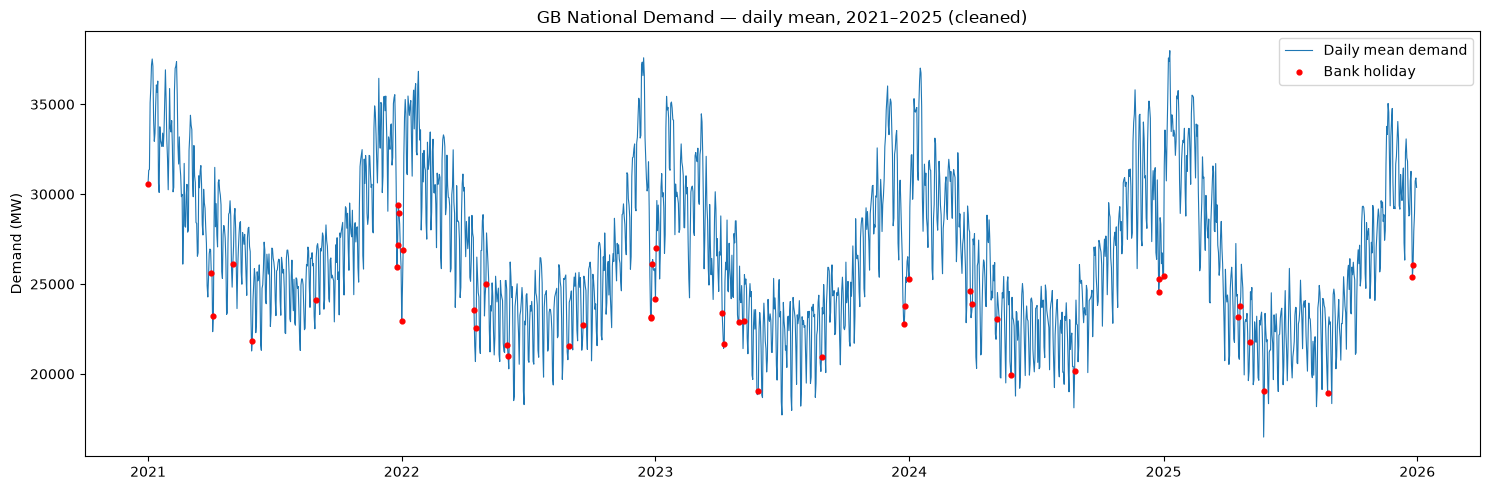

In [12]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily.index, daily["demand_mw"], linewidth=0.8, label="Daily mean demand")
hol = daily[daily["is_holiday"] == 1]
ax.scatter(hol.index, hol["demand_mw"], color="red", s=12, zorder=3, label="Bank holiday")
ax.set_title("GB National Demand — daily mean, 2021–2025 (cleaned)")
ax.set_ylabel("Demand (MW)")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Save

In [13]:
os.makedirs(processed_path, exist_ok=True)
out_file = f"{processed_path}/daily_demand.csv"
daily.to_csv(out_file)
print(f"Saved {daily.shape[0]} rows x {daily.shape[1]} columns to {out_file}")

Saved 1826 rows x 14 columns to ../data/processed/daily_demand.csv


## 8. Data-quality summary

In [14]:
print("DATA-QUALITY SUMMARY")
print(f"- Raw half-hourly rows: {len(df):,}")
print(f"- Days: {len(daily):,}, missing days: {missing_days}")
print(f"- Days with 46 periods (spring clock change): {(periods_per_day == 46).sum()}")
print(f"- Days with 50 periods (autumn clock change): {(periods_per_day == 50).sum()}")
print(f"- Duplicate timestamps with naive formula: {naive_ts.duplicated().sum()} (fixed with UTC-based timestamps)")
print(f"- Spikes flagged (>{SPIKE_THRESHOLD_MW:,} MW from rolling median): {df['is_spike'].sum()}, cleaned: {CLEAN_SPIKES}")
print(f"- Target: daily mean ND in MW (avoids clock-change distortion of daily sums)")

DATA-QUALITY SUMMARY
- Raw half-hourly rows: 87,648
- Days: 1,826, missing days: 0
- Days with 46 periods (spring clock change): 5
- Days with 50 periods (autumn clock change): 5
- Duplicate timestamps with naive formula: 10 (fixed with UTC-based timestamps)
- Spikes flagged (>8,000 MW from rolling median): 0, cleaned: True
- Target: daily mean ND in MW (avoids clock-change distortion of daily sums)
